## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
#histogram of the occurences of tokens

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Raffaella Alpaca

**Date:** 10/19/2026

In [3]:
# Your Phase 1 solution to the problem goes here.


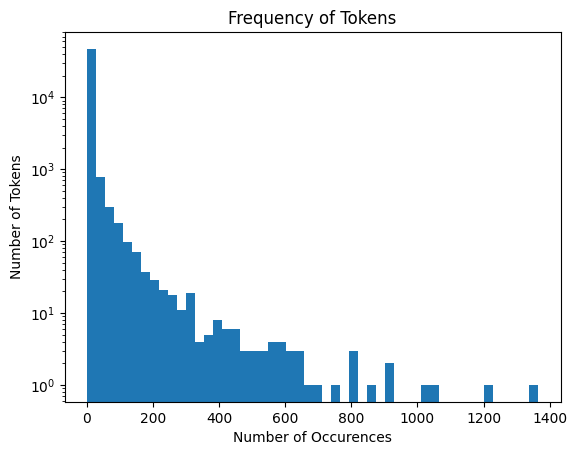

In [4]:
import matplotlib.pyplot as plt
#get frequency of each token
frequencies = list(token_count.values())
#plot histogram
#log scale to see the smaller bars better
plt.yscale('log')
plt.hist(frequencies, bins=50)
#title and labels
plt.title('Frequency of Tokens')
plt.xlabel('Number of Occurences')
plt.ylabel('Number of Tokens')
#show plot
plt.show()

The histogram is heavily right skewed. Most tokens appear only a few times, which is why there is a very tall bar on the left. Only a small number of tokens appear very frequently, creating a long tail toward the right. This shows that some words are used much more often than others in the emails.

Q2

In [5]:
import pandas as pd
#load email dataset
df = pd.read_parquet('Phishing_clean.parquet')
df.head()


,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
from sklearn.model_selection import train_test_split
# X contains all the word columns
X = df.drop(columns=["Email Type"])
# y contains what we want to predict
y = df["Email Type"]
#split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
#check how many emails are in each group
print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))


Training emails: 14907
Testing emails: 3727


In [7]:
from sklearn.linear_model import LinearRegression
#create the regression model
model = LinearRegression()
#training the model using the training emails
model.fit(X_train, y_train)
#calc R-squared for training data
train_r2 = model.score(X_train, y_train)
#calc R-squared for testing data
test_r2 = model.score(X_test, y_test)
print("Training R-squared:", train_r2)
print("Testing R-squared:", test_r2)


Training R-squared: 0.7670143724934355
Testing R-squared: 0.6658718438847919


In [8]:
#create a table with each word and its coefficient
coefficients = pd.DataFrame({
    "Word": X.columns,
    "Coefficient": model.coef_
})

#calc the absolute value of each coefficient
coefficients["Absolute Value"] = coefficients["Coefficient"].abs()
#sort from largest absolute value to smallest
coefficients = coefficients.sort_values(
    by="Absolute Value",
    ascending=False
)
#display the 10 words with the largest coefficients
print(coefficients.head(10))


                   Word  Coefficient  Absolute Value
835        intervention    -1.259257        1.259257
740           localized     0.824350        0.824350
2362            thermal     0.747006        0.747006
851             crawler     0.696167        0.696167
1504  background-image:    -0.622909        0.622909
1406         helvetica,     0.598560        0.598560
906               aging     0.594956        0.594956
1839              form.     0.576886        0.576886
2242              gray;    -0.574480        0.574480
1552           a:active     0.574480        0.574480


1.  I performed an 80/20 train-test split, with 14,907 emails in the training set and 3,727 emails in the testing set.
2. The training R² was 0.7670, and the testing R² was 0.6659. The model performs better on the training data than the testing data, which suggests some overfitting.

3.  The tokens with the largest coefficients in absolute value were intervention (-1.2593), localized (0.8244), thermal (0.7470), crawler (0.6962), and background-image: (-0.6229). These tokens have the strongest influence on the regression predictions when the other features are held constant. Positive coefficients increase the predicted scam score, while negative coefficients decrease it

Q3

In [9]:
from sklearn.decomposition import PCA
# PCA with 2 components
pca = PCA(n_components=2)
#apply PCA to the email token data
X_pca = pca.fit_transform(X)
#check the shape of the new data
print(X_pca.shape)

(18634, 2)


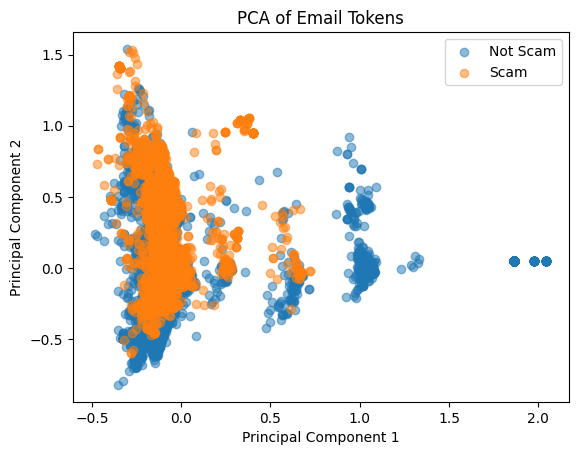

In [11]:
import matplotlib.pyplot as plt
# scatter plot for non-scam emails
plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label="Not Scam",
    alpha=0.5
)
#scatter plot for scam emails
plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label="Scam",
    alpha=0.5
)
#title and labels
plt.title("PCA of Email Tokens")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

#show which color represents each email type
plt.legend()
plt.show()

The PCA scatter plot shows that scam and non-scam emails overlap a lot, especially on the left side of the graph. However, there are some clusters on the right that are mostly non-scam emails. Most scam emails are concentrated in the main cluster, while some non-scam emails are more spread out. Overall, the first two principal components show some differences between the two types of emails, but they do not clearly separate them.

Q4

In [12]:
from sklearn.decomposition import PCA
# PCA with 2610 components
pca_large = PCA(n_components=2610)
#Fit PCA on training data and transform it
X_train_pca = pca_large.fit_transform(X_train)
#transforming testing data using the same PCA
X_test_pca = pca_large.transform(X_test)
print("Training shape:", X_train_pca.shape)
print("Testing shape:", X_test_pca.shape)


Training shape: (14907, 2610)
Testing shape: (3727, 2610)


In [13]:
from sklearn.linear_model import LinearRegression
#create a new linear regression model
model_pca = LinearRegression()
#train the model using the PCA training data
model_pca.fit(X_train_pca, y_train)
#calc R-squared for training data
train_r2_pca = model_pca.score(X_train_pca, y_train)

#calc R-squared for testing data
test_r2_pca = model_pca.score(X_test_pca, y_test)
print("PCA Training R-squared:", train_r2_pca)
print("PCA Testing R-squared:", test_r2_pca)


PCA Training R-squared: 0.7662326827745849
PCA Testing R-squared: 0.6683390643101164


In [14]:
#comparing the original regression and PCA regression
print("Original Training R-squared:", train_r2)
print("PCA Training R-squared:", train_r2_pca)

print("Original Testing R-squared:", test_r2)
print("PCA Testing R-squared:", test_r2_pca)


Original Training R-squared: 0.7670143724934355
PCA Training R-squared: 0.7662326827745849
Original Testing R-squared: 0.6658718438847919
PCA Testing R-squared: 0.6683390643101164


After performing PCA with 2,610 components, the training R² was **0.7662** and the testing R² was **0.6683**.

Compared to the original linear regression, which had a training R² of 0.7670 and a testing R² of 0.6659, the PCA model performed slightly worse on the training set but slightly better on the testing set.

Both models performed very similarly. This suggests that reducing the number of features using PCA did not significantly affect the model's performance, although it slightly improved the testing R².

Q5

Using principal components helps reduce the number of features while keeping most of the important information. This can make the regression simpler and reduce overfitting. In our results, the PCA model used fewer features but still performed almost the same as the original regression, with a slightly better testing R².

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:**
3b996df

- **AI tool and model used:** ChatGPT

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [10]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]